# Car price - JarvisTEC (`car_price`)

**Team members:** Anthony Jafeth Arias Robleto (2020007243), Randy Espinoza Downing (2021031263), Kenneth Jhoan Araya Arguedas (2024177221)
**Dataset:** [`car data.csv` (GitHub, amankharwal/Website-data)](https://raw.githubusercontent.com/amankharwal/Website-data/master/car%20data.csv), used-vehicle listings from the Indian marketplace CarDekho.

| Section | Points |
|---|---|
| 1. Problem analysis | 0.5 |
| 2. Data understanding | 0.5 |
| 3. Data exploration | 0.5 |
| 4. Model | 2 |
| 5. Evaluation | 1 |
| 6. Conclusion | 0.5 |

## Configuration

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

warnings.filterwarnings("ignore")

# ------------------------- EDIT THESE VALUES -------------------------
# Must match `name` in backend/models/<package>/adapter.py.
MODEL_NAME = "car_price"
# CSV path relative to training/<name>/ (data/ is git-ignored).
DATA_PATH = "../../data/car_price/car data.csv"
TARGET_COLUMN = "selling_price"  # lakh INR (1 lakh = 100,000 rupees)
TASK_TYPE = "regression"  # "classification" or "regression"
IS_TIME_SERIES = False  # True for bitcoin, avocado...: chronological split
DATE_COLUMN = None  # date column name when IS_TIME_SERIES is True
# 98 distinct model names in 301 rows: too sparse to learn from.
EXCLUDED_COLUMNS = ["car_name"]
SEED = 42
# ---------------------------------------------------------------------

ARTIFACTS = Path("../../artifacts")
ARTIFACTS.mkdir(exist_ok=True)
np.random.seed(SEED)
assert TASK_TYPE in ("classification", "regression")

## 1. Problem analysis

The goal is to estimate the **resale price of a used vehicle** from facts that any seller knows: the year of manufacture, the price of the same vehicle when new, the kilometers driven, the fuel type, the transmission, the type of seller and the number of previous owners. The estimate is useful to a person who wants to list a vehicle at a realistic price, and to a buyer or dealer who wants to check whether an asking price is reasonable.

- **Task type:** regression. The target `selling_price` is a continuous amount in **lakh** (1 lakh = 100,000 Indian rupees, INR), the unit used by the dataset.
- **Success metrics:** **RMSE** (root mean squared error) in lakh, which penalizes large errors, the costly ones when pricing a vehicle; **MAE** (mean absolute error) in lakh, the average size of the error; and **R²**, the share of the price variance explained. Because prices range from 0.1 to 35 lakh, the median percentage error is also reported. The model is compared with a baseline that always predicts the mean price.
- **Support:** Pudaruth (2014) and Gegic et al. (2019) predict used-car prices from the same kinds of attributes (age, mileage, fuel, transmission) with machine learning models.

## 2. Data understanding

In [2]:
df = pd.read_csv(DATA_PATH)
print("Rows, columns:", df.shape)
display(df.head())

Rows, columns: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# snake_case names: the same fields the API receives
# (backend/models/car_price/schema.py).
df.columns = [c.strip().lower() for c in df.columns]
display(df.head())

,car_name,year,selling_price,present_price,kms_driven,fuel_type,seller_type,transmission,owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [4]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(summary)
print("Duplicated rows:", df.duplicated().sum())
display(df.describe(include="all").T)

,dtype,missing,% missing,unique
car_name,str,0,0.0,98
year,int64,0,0.0,16
selling_price,float64,0,0.0,156
present_price,float64,0,0.0,147
kms_driven,int64,0,0.0,206
fuel_type,str,0,0.0,3
seller_type,str,0,0.0,2
transmission,str,0,0.0,2
owner,int64,0,0.0,3


Duplicated rows: 2


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
car_name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,301.0,NaN,NaN,NaN,2013.627907,2.891554,2003.0,2012.0,2014.0,2016.0,2018.0
selling_price,301.0,NaN,NaN,NaN,4.661296,5.082812,0.1,0.9,3.6,6.0,35.0
present_price,301.0,NaN,NaN,NaN,7.628472,8.644115,0.32,1.2,6.4,9.9,92.6
kms_driven,301.0,NaN,NaN,NaN,36947.20598,38886.883882,500.0,15000.0,32000.0,48767.0,500000.0
fuel_type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
owner,301.0,NaN,NaN,NaN,0.043189,0.247915,0.0,0.0,0.0,0.0,3.0


**Data description.** The dataset contains listings of used cars and motorcycles published on CarDekho (India). It has **301 vehicles** and 9 columns:

| Variable | Meaning | Type / unit |
|---|---|---|
| `car_name` | model name | text, 98 distinct values |
| `year` | year of manufacture | integer, 2003-2018 |
| `selling_price` | price at which the owner offers the vehicle (**target**) | lakh INR |
| `present_price` | current showroom price of the same vehicle when new | lakh INR |
| `kms_driven` | distance driven | km |
| `fuel_type` | fuel | categorical: `Petrol`, `Diesel`, `CNG` (compressed natural gas) |
| `seller_type` | who sells | categorical: `Dealer`, `Individual` |
| `transmission` | gearbox | categorical: `Manual`, `Automatic` |
| `owner` | number of previous owners | integer: 0, 1, 3 |

**Data quality:**
- **Missing values:** none. The `Pipeline` still imputes (median / mode) so that the backend accepts a request with a missing field.
- **Duplicates:** 2 identical rows (an Ertiga and a Fortuner, each listed twice). They are removed before splitting; **299 vehicles** remain.
- **`car_name` is excluded:** 98 distinct names in 301 rows (about 3 per name) is too sparse to learn from, and a user would have to say a name that the model has seen. Its information (the vehicle's segment) is largely carried by `present_price`.
- **Small, imbalanced categories:** there are only 2 CNG vehicles, 40 automatic ones and 11 with at least one previous owner. The model cannot learn reliable effects for them.
- **Extreme values:** one scooter with 500,000 km and one Land Cruiser with a showroom price of 92.6 lakh (the next highest is 36.2). They are plausible listings, so they are kept.
- The dataset mixes **cars and motorcycles**: 78 vehicles sell for less than 1 lakh.

## 3. Data exploration

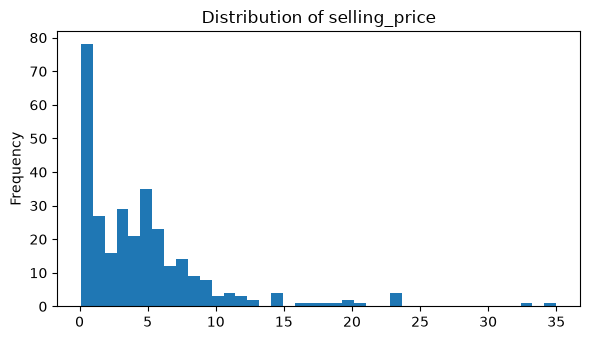

In [5]:
target = TARGET_COLUMN
fig, ax = plt.subplots(figsize=(6, 3.5))
if TASK_TYPE == "classification":
    df[target].value_counts().sort_index().plot(kind="bar", ax=ax)
    ax.set_title(f"Class distribution: {target}")
    shares = (df[target].value_counts(normalize=True) * 100).round(2)
    display(shares.rename("% of each class"))
else:
    df[target].plot(kind="hist", bins=40, ax=ax)
    ax.set_title(f"Distribution of {target}")
plt.tight_layout()
plt.show()

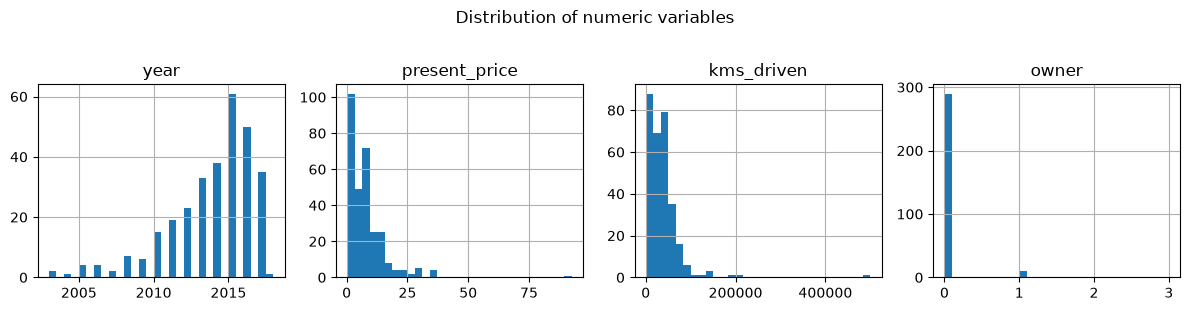

In [6]:
numeric_columns = [
    c for c in df.select_dtypes("number").columns
    if c not in EXCLUDED_COLUMNS + [target]
]
rows = (len(numeric_columns) + 3) // 4
df[numeric_columns].hist(bins=30, figsize=(12, 3 * rows), layout=(-1, 4))
plt.suptitle("Distribution of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

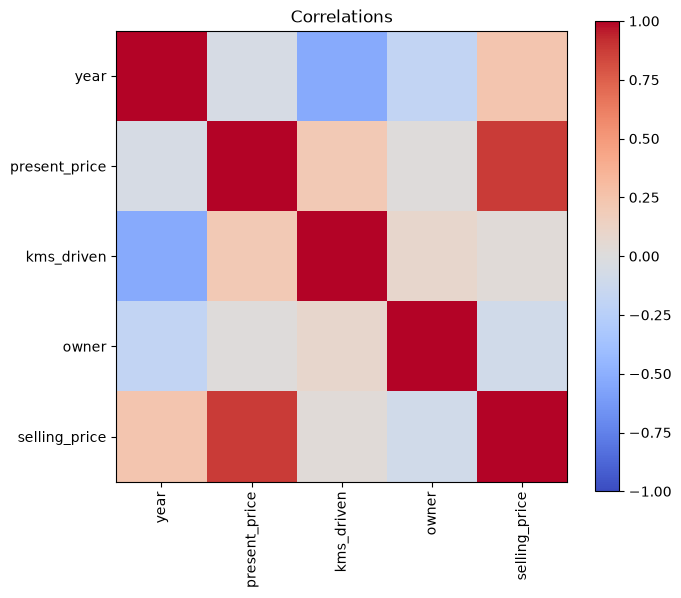

present_price    0.878983
year             0.236141
owner           -0.088344
kms_driven       0.029187
Name: correlation with the target, dtype: float64

In [7]:
if len(numeric_columns) > 1:
    corr = df[numeric_columns + [target]].select_dtypes("number").corr()
    fig, ax = plt.subplots(figsize=(7, 6))
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)))
    ax.set_xticklabels(corr.columns, rotation=90)
    ax.set_yticks(range(len(corr)))
    ax.set_yticklabels(corr.columns)
    plt.colorbar(image)
    ax.set_title("Correlations")
    plt.tight_layout()
    plt.show()
    if pd.api.types.is_numeric_dtype(df[target]):
        display(
            corr[target].drop(target)
            .sort_values(key=abs, ascending=False)
            .rename("correlation with the target")
        )

In [8]:
categorical_columns = [
    c for c in df.select_dtypes(exclude="number").columns
    if c not in EXCLUDED_COLUMNS + [target, DATE_COLUMN]
]
for column in categorical_columns[:6]:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().head(10))


fuel_type: 3 categories


fuel_type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64


seller_type: 2 categories


seller_type
Dealer        195
Individual    106
Name: count, dtype: int64


transmission: 2 categories


transmission
Manual       261
Automatic     40
Name: count, dtype: int64

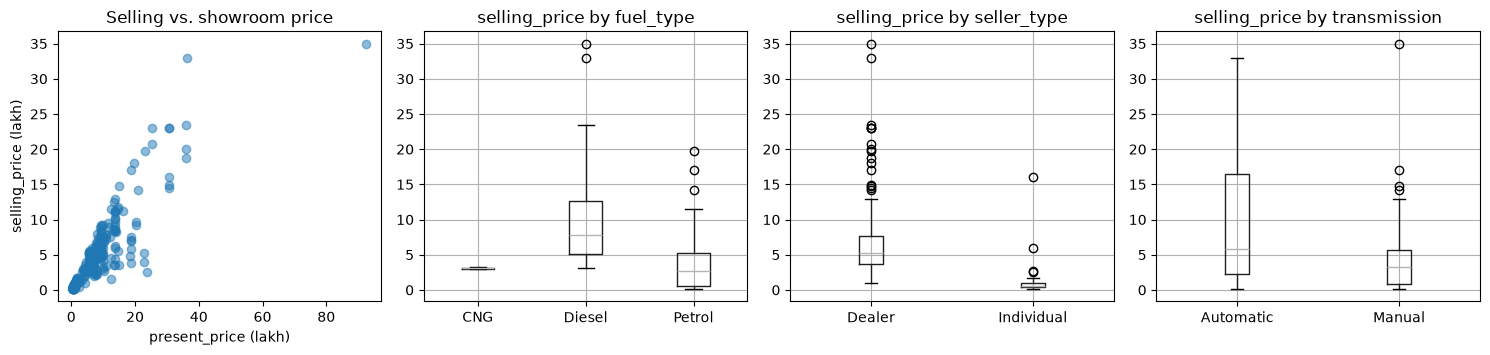

,count,median,mean
fuel_type,,,
CNG,2,3.10,3.10
Diesel,60,7.75,10.28
Petrol,239,2.65,3.26


,count,median,mean
seller_type,,,
Dealer,195,5.25,6.72
Individual,106,0.52,0.87


,count,median,mean
transmission,,,
Automatic,40,5.80,9.42
Manual,261,3.25,3.93


,count,median,mean
owner,,,
0,290,3.75,4.76
1,10,0.80,1.97
3,1,2.50,2.50


Skewness of selling_price: 2.49
Median selling/present ratio: 0.655


,count,median
year,,
2003,2,0.218
2004,1,0.121
2005,4,0.264
2006,4,0.193
2007,2,0.237
2008,7,0.273
2009,6,0.302
2010,15,0.378
2011,19,0.481


In [9]:
# Selling price against the showroom price and against each category.
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
axes[0].scatter(df["present_price"], df[target], alpha=0.5)
axes[0].set_xlabel("present_price (lakh)")
axes[0].set_ylabel("selling_price (lakh)")
axes[0].set_title("Selling vs. showroom price")
for ax, column in zip(axes[1:], ["fuel_type", "seller_type", "transmission"]):
    df.boxplot(column=target, by=column, ax=ax)
    ax.set_title(f"selling_price by {column}")
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()

for column in ["fuel_type", "seller_type", "transmission", "owner"]:
    display(
        df.groupby(column)[target].agg(["count", "median", "mean"]).round(2)
    )
print("Skewness of selling_price:", round(df[target].skew(), 2))
ratio = df[target] / df["present_price"]
print("Median selling/present ratio:", round(ratio.median(), 3))
display(
    df.assign(ratio=ratio).groupby("year")["ratio"]
    .agg(["count", "median"]).round(3)
)

**Exploration findings:**

- **Skewed target:** the median price is 3.6 lakh, but the mean is 4.66 and the maximum is 35 (skewness 2.49). A few expensive vehicles dominate squared-error metrics. This motivates trying a **log-transformed target** in section 4.
- **Showroom price dominates:** `present_price` has a correlation of **0.88** with the selling price. A used vehicle sells for a fraction of its new price; the median fraction is 0.66.
- **Depreciation is multiplicative:** that fraction falls steadily with age, from 0.91 for 2017 vehicles to 0.48 for 2011-2012 and between 0.12 and 0.26 for vehicles from before 2008 (with very few vehicles per year). `year` alone has a low linear correlation with the price (0.24) because its effect is a *percentage* of the new price, not a fixed amount. This is another reason to model the logarithm of the price, where percentage effects become additive.
- **Kilometers:** `kms_driven` has almost no linear correlation with the price (0.03). Mileage is related to age (correlation of -0.52 with `year`), so part of its information is already carried by `year`.
- **Categories:** diesel vehicles (median 7.75 vs. 2.65 lakh for petrol), vehicles sold by dealers (5.25 vs. 0.52 for individuals) and automatic vehicles (5.80 vs. 3.25 for manual) sell for more. These differences largely reflect *which* vehicles fall in each group rather than a premium for the category itself: individuals sell the cheaper vehicles (median showroom price of 0.84 lakh vs. 8.5 for dealers).
- **Owner:** the 10 vehicles with one previous owner sell for less (median 0.80 vs. 3.75 lakh with none), and a single vehicle has three previous owners; 11 vehicles are too few to draw a reliable conclusion.

**Preprocessing decisions:** drop duplicates; exclude `car_name`; impute with the median (numeric) or the mode (categorical); scale the numeric variables and one-hot encode the three categorical ones, all inside the `Pipeline`. No rows are removed as outliers.

## 4. Model

A baseline and several candidate models are compared with cross-validation on the training set, and the best one is chosen. All preprocessing is part of a `Pipeline`, so the backend can send raw data and no information from the test set leaks into training.

> **Note on the split:** this dataset is not a time series (`IS_TIME_SERIES = False`), so the 80/20 split is random and the cross-validation folds are shuffled. The chronological split and `TimeSeriesSplit` in the code apply only to the time-series models of the project.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    TimeSeriesSplit,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Duplicates removed before splitting, so no row is in both sets.
data = df.drop_duplicates().copy()
if IS_TIME_SERIES and DATE_COLUMN:
    data[DATE_COLUMN] = pd.to_datetime(data[DATE_COLUMN])
    data = data.sort_values(DATE_COLUMN).reset_index(drop=True)

dropped = [TARGET_COLUMN] + EXCLUDED_COLUMNS
dropped += [DATE_COLUMN] if DATE_COLUMN else []
X = data.drop(columns=dropped)
y = data[TARGET_COLUMN]
numeric_features = X.select_dtypes("number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

if IS_TIME_SERIES:
    cut = int(len(X) * 0.8)
    X_train, X_test = X.iloc[:cut], X.iloc[cut:]
    y_train, y_test = y.iloc[:cut], y.iloc[cut:]
    cv = TimeSeriesSplit(n_splits=5)
else:
    stratify = (
        y if TASK_TYPE == "classification" and y.value_counts().min() >= 2
        else None
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=SEED, stratify=stratify
    )
    cv = (
        StratifiedKFold(5, shuffle=True, random_state=SEED)
        if stratify is not None
        else KFold(5, shuffle=True, random_state=SEED)
    )

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), numeric_features),
    ("cat", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])
print(f"Train: {X_train.shape}  Test: {X_test.shape}")
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)

Train: (239, 7)  Test: (60, 7)
Numeric: ['year', 'present_price', 'kms_driven', 'owner']
Categorical: ['fuel_type', 'seller_type', 'transmission']


In [11]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge


def log_target(estimator):
    # Train on log(1 + price) and predict back in lakh: the price is
    # right-skewed and its effects are multiplicative (section 3).
    return TransformedTargetRegressor(
        regressor=estimator, func=np.log1p, inverse_func=np.expm1
    )


base_models = {
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=SEED, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=SEED),
}
candidates = {"Baseline": DummyRegressor(strategy="mean")}
for name, estimator in base_models.items():
    candidates[name] = estimator
    candidates[f"{name} (log target)"] = log_target(estimator)
# Negative RMSE in lakh for every candidate: higher is better.
scoring = "neg_root_mean_squared_error"

score_column = f"{scoring} (mean)"
rows = []
for name, estimator in candidates.items():
    pipeline = Pipeline([("prep", preprocessor), ("model", estimator)])
    scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1
    )
    r2_scores = cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="r2", n_jobs=1
    )
    rows.append({
        "model": name,
        score_column: scores.mean(),
        "std": scores.std(),
        "r2 (mean)": r2_scores.mean(),
    })
comparison = (
    pd.DataFrame(rows)
    .sort_values(score_column, ascending=False)
    .reset_index(drop=True)
)
display(comparison)

,model,neg_root_mean_squared_error (mean),std,r2 (mean)
0,Gradient Boosting (log target),-1.481469,1.256044,0.896305
1,Random Forest,-1.488271,0.914913,0.898355
2,Random Forest (log target),-1.547164,1.072860,0.891017
3,Gradient Boosting,-1.572982,1.120927,0.886422
4,Ridge,-1.638444,0.430674,0.885801
5,Baseline,-4.865677,0.930611,-0.006685
6,Ridge (log target),-20.938537,38.905214,-43.176364


**Model choice.** Seven candidates were compared with 5-fold cross-validation on the training set (239 vehicles), using scikit-learn (Pedregosa et al., 2011). All of them are scored by RMSE in lakh:
- a **baseline** that always predicts the mean price;
- **Ridge**, a regularized linear model;
- two tree ensembles: **Random Forest** (Breiman, 2001) and **Gradient Boosting** (Friedman, 2001);
- each of these three models again with a **log target**: the model is trained on `log(1 + price)` and its predictions are converted back to lakh (`TransformedTargetRegressor`), so the scores are comparable.

| Model | CV RMSE (lakh) | CV R² |
|---|---|---|
| Gradient Boosting (log target) | **1.48** | 0.896 |
| Random Forest | 1.49 | 0.898 |
| Random Forest (log target) | 1.55 | 0.891 |
| Gradient Boosting | 1.57 | 0.886 |
| Ridge | 1.64 | 0.886 |
| Baseline | 4.87 | -0.007 |
| Ridge (log target) | 20.94 | -43.2 |

The three best models are within the cross-validation noise of each other: their mean RMSE differs by less than 0.07 lakh, while the standard deviation of the RMSE across the five folds is about 1 lakh (1.26 for Gradient Boosting on the log target, 0.91 for Random Forest and 1.07 for Random Forest on the log target), because a fold's RMSE depends on which of the few expensive vehicles it contains. **Gradient Boosting on the log target** is chosen. It has the lowest RMSE, although by a negligible margin, and the exploration gives a reason to prefer it: depreciation acts as a percentage of the new price.

**Ridge with a log target fails badly** (RMSE 20.9). A model that is linear in log space is exponential in price space, so a vehicle whose showroom price is far from the rest (the Land Cruiser, 92.6 lakh) is extrapolated to an absurd value. Tree models cannot predict beyond the range of prices seen in training, which makes them safer here.

**Hyperparameter tuning.** Only the selected model, Gradient Boosting on the log target, was tuned; the other candidates were compared with their default settings, so the comparison above does not show how they would rank after tuning. `RandomizedSearchCV` evaluated 20 combinations with the same cross-validation, on the training set only:
- **Searched hyperparameters:** number of trees, learning rate, tree depth and row subsampling.
- **Best combination:** 400 trees, learning rate 0.03, `max_depth=2` and `subsample=0.8`, that is, many shallow trees with a small step, a conservative setting that suits a small dataset.
- **Result:** the cross-validated RMSE improved from 1.48 to 1.38 lakh, so the tuned model was adopted. This gain (0.10 lakh) is also much smaller than the standard deviation across folds.

In [12]:
BEST = comparison.loc[~comparison["model"].eq("Baseline"), "model"].iloc[0]
print("Chosen model:", BEST)
final_pipeline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates[BEST]),
])
final_pipeline.fit(X_train, y_train)

Chosen model: Gradient Boosting (log target)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['year','present_price','kms_driven',...,'seller_type','transmission', 'owner']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis

In [13]:
# Hyperparameter tuning of the chosen model: cross-validation on TRAIN only.
from sklearn.model_selection import RandomizedSearchCV

SEARCH_SPACES = {
    "Random Forest": {
        "n_estimators": [200, 400],
        "max_depth": [None, 10, 20],
        "min_samples_leaf": [1, 2, 4],
        "max_features": ["sqrt", 0.5, 1.0],
    },
    "Gradient Boosting": {
        "n_estimators": [100, 200, 400],
        "learning_rate": [0.03, 0.1],
        "max_depth": [2, 3, 4],
        "subsample": [0.8, 1.0],
    },
    "Ridge": {"alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
}
LOG_SUFFIX = " (log target)"
# Parameters of a log-target model live one level deeper (the regressor).
PREFIX = "model__regressor__" if BEST.endswith(LOG_SUFFIX) else "model__"
space = {
    PREFIX + key: values
    for key, values in SEARCH_SPACES[BEST.removesuffix(LOG_SUFFIX)].items()
}

HYPERPARAMETERS = {}
search = RandomizedSearchCV(
    final_pipeline,
    space,
    n_iter=min(20, int(np.prod([len(v) for v in space.values()]))),
    cv=cv,
    scoring=scoring,
    random_state=SEED,
    n_jobs=1,
)
search.fit(X_train, y_train)
untuned = comparison.loc[comparison["model"].eq(BEST), score_column].iloc[0]
print(
    f"{scoring} CV untuned: {untuned:.4f} | tuned: {search.best_score_:.4f}"
)
if search.best_score_ > untuned:
    final_pipeline = search.best_estimator_
    HYPERPARAMETERS = {
        key.removeprefix(PREFIX): value
        for key, value in search.best_params_.items()
    }
print("Hyperparameters used:", HYPERPARAMETERS or "defaults")

neg_root_mean_squared_error CV untuned: -1.4815 | tuned: -1.3808
Hyperparameters used: {'subsample': 0.8, 'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.03}


## 5. Evaluation

The chosen model is evaluated on the held-out test set, which was not used for training, model selection or tuning. Any other model scored on the test set below is shown for reference only and did not influence a choice.

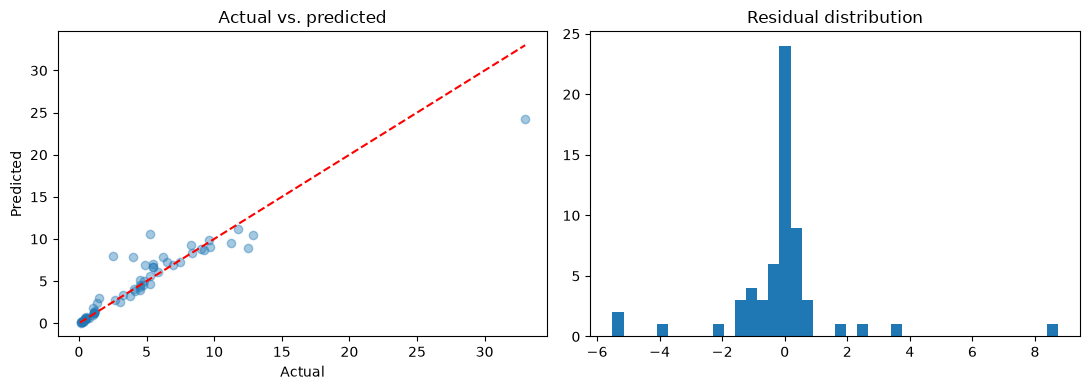

rmse    1.7871
mae     0.8724
r2      0.8761
Name: test metrics, dtype: float64

Baseline RMSE on test: 5.0768


In [14]:
from sklearn import metrics

predictions = final_pipeline.predict(X_test)

if TASK_TYPE == "classification":
    test_metrics = {
        "accuracy": metrics.accuracy_score(y_test, predictions),
        "f1_macro": metrics.f1_score(y_test, predictions, average="macro"),
        "precision_macro": metrics.precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "recall_macro": metrics.recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
    }
    print(metrics.classification_report(
        y_test, predictions, zero_division=0
    ))
    fig, ax = plt.subplots(figsize=(5, 4.5))
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title("Confusion matrix")
    plt.tight_layout()
    plt.show()
else:
    test_metrics = {
        "rmse": metrics.mean_squared_error(y_test, predictions) ** 0.5,
        "mae": metrics.mean_absolute_error(y_test, predictions),
        "r2": metrics.r2_score(y_test, predictions),
    }
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].scatter(y_test, predictions, alpha=0.4)
    limits = [
        min(y_test.min(), predictions.min()),
        max(y_test.max(), predictions.max()),
    ]
    ax[0].plot(limits, limits, "r--")
    ax[0].set_xlabel("Actual")
    ax[0].set_ylabel("Predicted")
    ax[0].set_title("Actual vs. predicted")
    ax[1].hist(y_test - predictions, bins=40)
    ax[1].set_title("Residual distribution")
    plt.tight_layout()
    plt.show()

test_metrics = {k: round(float(v), 4) for k, v in test_metrics.items()}
display(pd.Series(test_metrics, name="test metrics"))

# Baseline on the same test set, to check the model really adds value.
baseline = Pipeline([
    ("prep", preprocessor),
    ("model", candidates["Baseline"]),
]).fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)
if TASK_TYPE == "classification":
    baseline_score = metrics.f1_score(
        y_test, baseline_predictions, average="macro"
    )
    print("Baseline f1_macro on test:", round(baseline_score, 4))
else:
    baseline_score = (
        metrics.mean_squared_error(y_test, baseline_predictions) ** 0.5
    )
    print("Baseline RMSE on test:", round(baseline_score, 4))

cat__fuel_type_CNG             0.0000
num__owner                     0.0000
cat__seller_type_Individual    0.0003
cat__transmission_Manual       0.0005
cat__transmission_Automatic    0.0007
cat__fuel_type_Petrol          0.0009
cat__fuel_type_Diesel          0.0028
num__kms_driven                0.0037
cat__seller_type_Dealer        0.0043
num__year                      0.0598
num__present_price             0.9269
Name: Feature importance, dtype: float64

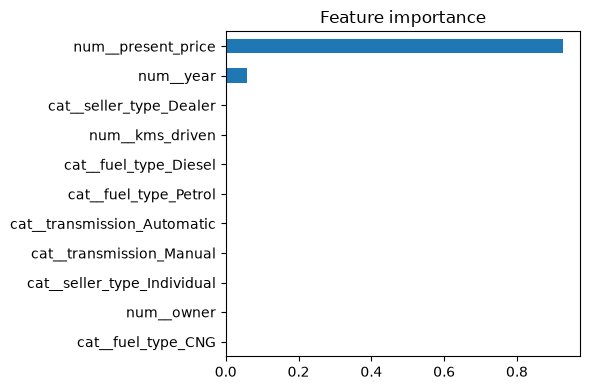

In [15]:
# Feature importance (when the model exposes it).
estimator = final_pipeline.named_steps["model"]
# A log-target model wraps the fitted regressor.
estimator = getattr(estimator, "regressor_", estimator)
feature_names = final_pipeline.named_steps["prep"].get_feature_names_out()
if hasattr(estimator, "feature_importances_"):
    weights, title = estimator.feature_importances_, "Feature importance"
else:
    weights, title = estimator.coef_, "Coefficients (log price, scaled inputs)"
importance = pd.Series(weights, index=feature_names).sort_values(key=abs)
display(importance.round(4).rename(title))
importance.tail(12).plot(kind="barh", figsize=(6, 4), title=title)
plt.tight_layout()
plt.show()

In [16]:
# Error by price segment: is the model equally reliable for cheap and
# expensive vehicles?
errors = pd.DataFrame({
    "actual": y_test,
    "predicted": predictions,
    "abs_error": (y_test - predictions).abs(),
})
errors["pct_error"] = errors["abs_error"] / errors["actual"] * 100
errors["segment"] = pd.cut(
    errors["actual"], [0, 1, 5, 10, np.inf],
    labels=["< 1 lakh", "1-5 lakh", "5-10 lakh", "> 10 lakh"],
)
display(
    errors.groupby("segment", observed=True)
    .agg(n=("actual", "size"), mae=("abs_error", "mean"),
         median_pct_error=("pct_error", "median"))
    .round(3)
)
print("Median % error:", round(errors["pct_error"].median(), 2))
display(errors.sort_values("abs_error", ascending=False).head(5).round(2))

# Untuned candidate on the same test set, for reference only.
untuned_model = Pipeline([
    ("prep", preprocessor), ("model", candidates[BEST]),
]).fit(X_train, y_train)
untuned_predictions = untuned_model.predict(X_test)
print(
    "Untuned", BEST, "RMSE on test:",
    round(metrics.mean_squared_error(y_test, untuned_predictions) ** 0.5, 4),
    "R2:", round(metrics.r2_score(y_test, untuned_predictions), 4),
)

,n,mae,median_pct_error
segment,,,
< 1 lakh,14,0.073,18.107
1-5 lakh,24,0.784,11.794
5-10 lakh,17,0.909,7.312
> 10 lakh,5,3.411,19.212


Median % error: 12.32


,actual,predicted,abs_error,pct_error,segment
64,33.00,24.27,8.73,26.45,> 10 lakh
85,2.50,8.01,5.51,220.30,1-5 lakh
78,5.25,10.58,5.33,101.45,5-10 lakh
94,4.00,7.86,3.86,96.55,1-5 lakh
83,12.50,8.95,3.55,28.44,> 10 lakh


Untuned Gradient Boosting (log target) RMSE on test: 1.9661 R2: 0.85


**Interpretation.** On the test set (60 vehicles not seen during training) the model reaches an **RMSE of 1.79 lakh**, an **MAE of 0.87 lakh** and an **R² of 0.876**, against a baseline RMSE of **5.08 lakh**. The median percentage error is **12 %** of the actual price. The test R² is slightly below the cross-validated one (about 0.90), which is expected with only 60 test vehicles: a single expensive vehicle moves the result.

**Error analysis:**
- **By price segment:** the model is most accurate between 5 and 10 lakh (median error 7 %) and between 1 and 5 lakh (12 %). It is less reliable at the extremes: below 1 lakh (18 %, although the absolute error is very small, 0.07 lakh) and above 10 lakh (19 %, with only 5 test vehicles).
- **Largest errors:** a 2017 Fortuner listed at 33 lakh was predicted at 24.3 lakh; the model underestimates the most expensive vehicles because the training set has very few like it. Three old premium sedans (a 2006 Camry and two Corolla Altis from 2008 and 2010, with showroom prices of about 23 lakh and selling prices of 2.5 to 5.25 lakh) were overestimated by 3.9 to 5.5 lakh. Old vehicles with a high showroom price are rare in the data, so their heavy depreciation is not fully learned.
- **Residuals:** most are close to zero, with a few large values on both sides caused by the vehicles above.

**Effect of tuning.** The untuned model reached a test RMSE of 1.97 lakh (R² 0.85); the tuned one reached 1.79 lakh (R² 0.876). The improvement seen in cross-validation carried over to the test set. The model was chosen by cross-validation only; the test set was not used to select it.

**Feature importance.** `present_price` accounts for **0.93** of the importance and `year` for 0.06; every other feature is below 0.01. In effect, the model learned "showroom price times a depreciation factor that depends on age". Fuel, transmission and seller type add almost nothing once the showroom price is known, which is consistent with the interpretation in section 3 that their price differences come from the kind of vehicle in each group.

**Possible causes of error:** only 299 vehicles; cars and motorcycles mixed in one dataset; few expensive vehicles and few with previous owners; no information on condition, accidents, service history or exact model; and the selling price is a listing price, not necessarily the final sale price.

## Export for the backend

In [17]:
joblib.dump(final_pipeline, ARTIFACTS / f"{MODEL_NAME}.joblib")

# Typical input: becomes the `default_input` of the backend adapter.
example = X_train.median(numeric_only=True).round(3).to_dict()
for column in categorical_features:
    example[column] = X_train[column].mode().iloc[0]

meta = {
    "model": BEST,
    "hyperparameters": HYPERPARAMETERS,
    "task": TASK_TYPE,
    "features": X.columns.tolist(),
    "test_metrics": test_metrics,
    "default_input": example,
    "sklearn_version": sklearn.__version__,
}
if TASK_TYPE == "classification":
    meta["classes"] = sorted(y.unique().tolist())
meta_path = ARTIFACTS / f"{MODEL_NAME}.meta.json"
meta_path.write_text(json.dumps(meta, indent=2, default=str))

print(f"Saved artifacts/{MODEL_NAME}.joblib and {meta_path.name}")
print("\nCopy to backend/models/<package>/ (schema.py / default_input):")
print(json.dumps(example, indent=2, default=str))

Saved artifacts/car_price.joblib and car_price.meta.json

Copy to backend/models/<package>/ (schema.py / default_input):
{
  "year": 2014.0,
  "present_price": 5.97,
  "kms_driven": 30753.0,
  "owner": 0.0,
  "fuel_type": "Petrol",
  "seller_type": "Dealer",
  "transmission": "Manual"
}


## 6. Conclusion

A Gradient Boosting model trained on the logarithm of the price estimates the resale price of a used vehicle with a **test RMSE of 1.79 lakh, an MAE of 0.87 lakh and an R² of 0.88**. Its RMSE is about a third of the baseline's (5.08 lakh), and its median error is 12 % of the price. Its behavior is easy to explain: the predicted price is the showroom price of the vehicle reduced by a factor that grows with age. It is useful as a **reference price** to start a negotiation, not as an appraisal.

**Limitations:**
- The dataset is small (299 vehicles) and comes from a single Indian marketplace, with vehicles up to 2018; prices are in lakh INR and do not transfer to another country or year without retraining.
- The model depends on knowing the showroom price of the vehicle; without it, it has little to work with.
- It is less reliable for vehicles above about 10 lakh (median error of 19 % on only 5 test vehicles) and for old premium vehicles.
- Categories with few examples (CNG, previous owners) are not really learned.

**Future improvements:**
- Train on a larger set of listings that also describes the engine and the exact model.
- Use separate models, or an explicit flag, for cars and motorcycles.
- Use the vehicle's age at the listing date instead of the year, so that the model does not become outdated.
- Predict a price range (quantile regression) instead of a single value.

**Voice commands for this model:** *"JarvisTEC, car price"*, *"JarvisTEC, how much is my car worth"*, *"JarvisTEC, used car price"*

### References

- Pudaruth, S. (2014). Predicting the price of used cars using machine learning techniques. *International Journal of Information & Computation Technology, 4*(7), 753-764.
- Gegic, E., Isakovic, B., Keco, D., Masetic, Z., & Kevric, J. (2019). Car price prediction using machine learning techniques. *TEM Journal, 8*(1), 113-118. https://doi.org/10.18421/TEM81-16
- Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189-1232. https://doi.org/10.1214/aos/1013203451
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5-32. https://doi.org/10.1023/A:1010933404324
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.